# SAPP representative days rebuilt from the 2024 hourly load

This notebook rebuilds the EPM time structure of `data_sapp_nuc_rsa_moz`: `pHours`, `pDemandProfile` and `pVREProfile`, plus the two other files indexed by representative day, `pVREgenProfile` and `pTradePrice`. It uses the 2024 hourly load sent by SAPP (`Load_data_SAPP.xlsx`) and ERA5 solar and wind series for the same year, run through `representativedays_pipeline.py`.

**Why.** The input check flagged two problems in the current demand profiles:

- **Profile maximum below 1** in 16 zones (0.81 in Zimbabwe). EPM builds hourly demand as profile × forecast peak, so the model peak was up to 19% below the forecast peak, and the planning reserve was sized on that lower peak.
- **Negative hourly demand** in DRC and the three Mozambique zones. The forecast's load factor is much lower than the profile's, and the energy correction in `generate_demand.gms` pushes the low hours below zero.

**Correction applied in the pipeline.** The pipeline already adds a `max_Load` special day, but it is the day closest to the centre of the highest-load cluster, computed on load **summed over all zones**. It follows South Africa and rarely contains anyone's peak hour. The new option `peak_load_days=True` adds the actual peak day of each country as a special day of weight 1.

The notebook writes candidate EPM files to `output/sapp_2024/epm/`. It does not change the model's input folder.

## 0. Settings

In [1]:
import os, re, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path.cwd()
if not (BASE / 'representativedays_pipeline.py').exists():
    BASE = BASE / 'pre-analysis' / 'representative_days'
os.chdir(BASE)                      # the pipeline resolves gams/ from the working directory
sys.path.insert(0, str(BASE.parent))
from representative_days.representativedays_pipeline import run_representative_days_pipeline

ROOT = BASE.parents[1]
EPM_INPUT = ROOT / 'epm' / 'input' / 'data_sapp_nuc_rsa_moz'      # read only
REF_INPUT = BASE / 'input' / 'sapp' / 'reference_16d'             # 16-day study files before this rebuild (git 8ce0cbdb^)
LOAD_XLSX = BASE / 'input' / 'sapp' / 'Load_data_SAPP.xlsx'       # copy of the SAPP file
ERA5_2024 = ROOT / 'pre-analysis' / 'climate_years' / 'output' / 'sapp_2024' / 'hourly'
ERA5_HIST = ROOT / 'pre-analysis' / 'climate_years' / 'output' / 'sapp' / 'hourly'
ERA5_OFFSHORE = ROOT / 'pre-analysis' / 'climate_years' / 'output' / 'sapp_2024_offshore' / 'raw'   # ERA5 at offshore sites (UTC)
OFFSHORE_SITES = ROOT / 'pre-analysis' / 'climate_years' / 'zone_sites_sapp_offshore.csv'
REUSE_RUNS = True               # reuse the day selection saved in output/sapp_2024/run_* (set False after changing load or selection sites)
DRC_SYNTHETIC = BASE / 'input' / 'sapp' / 'drc_synthetic_demand_ssp2-2.6_2030_era5_2018.csv'   # Zenodo 6569890, region CD
DRC_MINING_FLAT_SHARE = 0.9     # DRC_South (mines): 90% constant + 10% of the DRC shape
OUT = BASE / 'output' / 'sapp_2024'
EPM_OUT = OUT / 'epm'
EPM_OUT.mkdir(parents=True, exist_ok=True)
EPM_OUT_16 = OUT / 'epm_16d'                   # 16-day variant (section 10)
EPM_OUT_16.mkdir(parents=True, exist_ok=True)

YEAR = 2024
SEASONS = {m: (m - 1) // 3 + 1 for m in range(1, 13)}   # Q1 = Jan-Mar ... Q4 = Oct-Dec, as the current pHours
N_REPR_DAYS = 2                 # representative days per season chosen by the optimisation (special days come on top)
BLACKOUT_THRESHOLD = 0.5        # an hour below 50% of the median of the same hour over +-7 days is treated as an outage
SPIKE_REF, SPIKE_NEIGHBOUR = 1.2, 1.15   # isolated spike: > 1.2 x that median and > 1.15 x both neighbouring hours

pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})
warnings.filterwarnings('ignore', category=FutureWarning)

## 1. Read the SAPP hourly load

The workbook has one block of columns per country. Where a block has both **Original** and **Adapted** columns, *Adapted* is SAPP's corrected series and is used here. South Africa has only *Original*, and Malawi a single *Total* column.

In [2]:
raw = pd.read_excel(LOAD_XLSX, header=None)
titles = {c: v for c, v in raw.iloc[1].items() if isinstance(v, str)}
header = raw.iloc[2]
blocks = sorted(titles)
load_raw, info = {}, []
for i, c0 in enumerate(blocks):
    c1 = blocks[i + 1] if i + 1 < len(blocks) else raw.shape[1]
    name = re.match(r'([A-Z ]+?)\s+(HOURLY|Hourly|20\d\d)', titles[c0]).group(1).strip()
    country = {'SOUTH AFRICA': 'South_Africa'}.get(name, name.title())
    cols = {header[c]: c for c in range(c0, c1) if isinstance(header[c], str)}
    value_col = next(k for k in ('Adapted', 'Original', 'Total') if k in cols)
    df = pd.DataFrame({'month': raw.iloc[3:, cols['Month']], 'day': raw.iloc[3:, cols['Month-Day']],
                       'hour': raw.iloc[3:, cols['Hour-day']], 'value': raw.iloc[3:, cols[value_col]]})
    if 'Original' in cols and value_col != 'Original':
        df['original'] = raw.iloc[3:, cols['Original']]
    df = df.apply(pd.to_numeric, errors='coerce').dropna(subset=['month', 'day', 'hour', 'value'])
    df = df.astype({'month': int, 'day': int, 'hour': int}).reset_index(drop=True)
    load_raw[country] = df
    info.append(dict(country=country, column_used=value_col, rows=len(df),
                     starts=f"{df.month.iloc[0]:02d}-{df.day.iloc[0]:02d}", hour_labels=f"{df.hour.min()}-{df.hour.max()}",
                     duplicated_hours=int(df.duplicated(['month', 'day', 'hour']).sum()),
                     feb29_hours=int(((df.month == 2) & (df.day == 29)).sum()),
                     hours_corrected_by_SAPP=int((df.original - df.value).abs().gt(1e-6).sum()) if 'original' in df else None,
                     original_min_MW=round(df.original.min(), 1) if 'original' in df else None))
info = pd.DataFrame(info).set_index('country')
info

,column_used,rows,starts,hour_labels,duplicated_hours,feb29_hours,hours_corrected_by_SAPP,original_min_MW
country,,,,,,,,
Eswatini,Adapted,8784,01-01,1-24,0,24,5.000,0.000
Lesotho,Adapted,8784,04-01,1-24,24,0,0.000,57.500
Malawi,Total,8784,01-01,1-24,0,24,NaN,NaN
Mozambique,Adapted,8784,01-01,1-24,0,24,0.000,294.600
Namibia,Adapted,8784,01-01,1-24,0,24,60.000,-926.600
Zimbabwe,Adapted,8784,01-01,1-24,0,24,0.000,803.000
Zambia,Adapted,8784,01-01,1-24,0,24,12.000,0.000
Tanzania,Adapted,8784,01-01,1-24,0,24,337.000,15.700
South_Africa,Original,8784,01-01,1-24,0,24,NaN,NaN


**What the table shows**

- Hour labels run 1–24, meaning hour ending. They are converted to 0–23 (hour beginning) before the pipeline.
- **Lesotho** starts on 1 April. Its year is April 2024 to March 2025, with 1 April repeated at the end and no 29 February. The duplicate day is dropped and the months are put in calendar order, so January–March come from 2025. Weekdays are therefore shifted for those months, which has little effect on seasonal profiles.
- All other countries are calendar 2024, a leap year: 29 February is dropped to keep 365 days.
- SAPP's *Adapted* columns already remove zeros and negative values from the *Original* data, for example Namibia down to −927 MW and Eswatini and Zambia at 0 MW.

## 2. Clean the series

1. Drop duplicated hours (Lesotho) and 29 February, then sort in calendar order (365 days × 24 hours).
2. Replace outage hours. An hour is treated as a blackout or load-shedding hour when it is below **50%** of the median of the same hour of the day over the surrounding 15 days. It is replaced by that median. A higher threshold starts catching normal low-load hours, such as holidays.
3. Replace isolated one-hour spikes. An hour is treated as a spike when it is above **1.2 ×** that median **and** above **1.15 ×** both neighbouring hours. It is replaced by the mean of the two neighbours. Sustained high load, such as a cold evening, rises over several hours and is not affected.

In [3]:
def clean(df):
    df = df.drop_duplicates(['month', 'day', 'hour'], keep='first')
    df = df[~((df.month == 2) & (df.day == 29))].sort_values(['month', 'day', 'hour']).reset_index(drop=True)
    assert len(df) == 8760, len(df)
    M = df.value.to_numpy(dtype=float).reshape(365, 24)
    ref = pd.DataFrame(M).rolling(15, center=True, min_periods=5).median().to_numpy()
    low = M < BLACKOUT_THRESHOLD * ref
    v = np.where(low, ref, M).ravel()
    # Isolated one-hour spikes: well above the usual level of that hour AND above both neighbouring hours
    prev, nxt = np.r_[v[1], v[:-1]], np.r_[v[1:], v[-2]]
    spike = (v > SPIKE_REF * ref.ravel()) & (v > SPIKE_NEIGHBOUR * np.maximum(prev, nxt))
    df['clean'] = np.where(spike, (prev + nxt) / 2, v)
    df['replaced'] = low.ravel()
    df['spike'] = spike
    return df

load = {c: clean(df) for c, df in load_raw.items()}

def stats(v):
    return dict(peak_MW=v.max(), energy_GWh=v.sum() / 1e3, load_factor=v.sum() / (v.max() * len(v)), min_over_peak=v.min() / v.max())

rows = []
for c, df in load.items():
    s_raw, s_clean = stats(df.value), stats(df['clean'])
    pk = df.loc[df['clean'].idxmax()]
    sp = df.loc[df.spike]
    rows.append(dict(country=c, hours_replaced=int(df.replaced.sum()), days_affected=int(df.replaced.values.reshape(365, 24).any(1).sum()),
                     spikes_removed=len(sp), spikes_at=', '.join(f"{int(r.month):02d}-{int(r.day):02d} h{int(r.hour)}" for r in sp.itertuples()),
                     min_over_peak_before=s_raw['min_over_peak'], min_over_peak_after=s_clean['min_over_peak'],
                     peak_MW=s_clean['peak_MW'], energy_GWh=s_clean['energy_GWh'], load_factor=s_clean['load_factor'],
                     peak_time=f"{int(pk.month):02d}-{int(pk.day):02d} h{int(pk.hour)}"))
load_stats = pd.DataFrame(rows).set_index('country').sort_values('load_factor', ascending=False)
load_stats

,hours_replaced,days_affected,spikes_removed,spikes_at,min_over_peak_before,min_over_peak_after,peak_MW,energy_GWh,load_factor,peak_time
country,,,,,,,,,,
South_Africa,0,0,0,,0.490,0.490,36398.960,242108.479,0.759,07-04 h19
Angola,0,0,0,,0.507,0.507,2424.030,16061.946,0.756,05-02 h21
Namibia,0,0,0,,0.495,0.495,672.081,4278.183,0.727,06-04 h20
Mozambique,27,3,0,,0.259,0.351,1136.593,7194.188,0.723,09-09 h19
Malawi,8,4,0,,0.009,0.316,386.740,2432.818,0.718,09-18 h19
Botswana,2,1,0,,0.282,0.305,675.050,4143.653,0.701,06-04 h19
Zimbabwe,0,0,2,"08-15 h24, 11-10 h23",0.436,0.437,1837.000,11269.229,0.700,05-12 h19
Tanzania,26,5,3,"02-24 h2, 07-15 h24, 10-14 h2",0.014,0.287,1888.721,11581.941,0.700,11-26 h20
Zambia,0,0,0,,0.354,0.354,2285.723,13879.784,0.693,02-22 h20


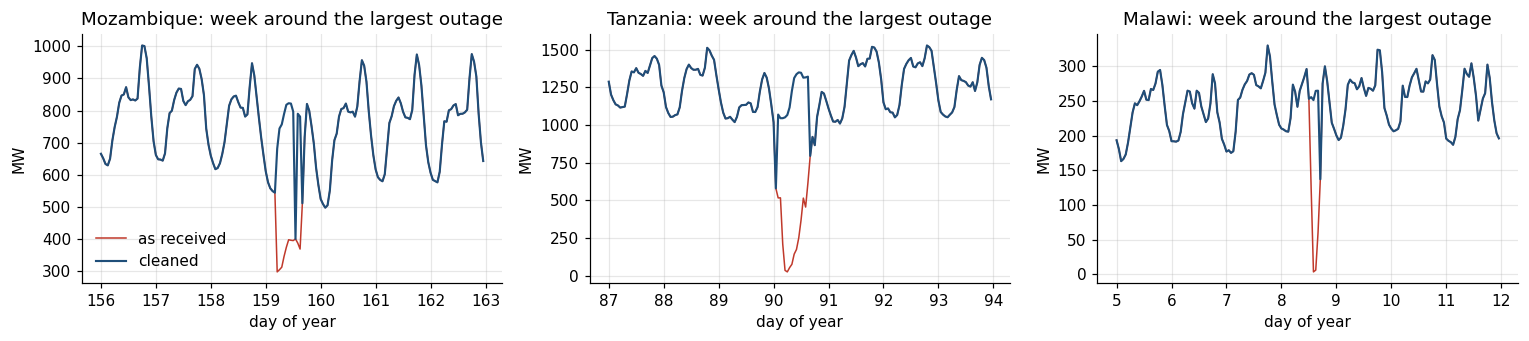

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, c in zip(axes, ['Mozambique', 'Tanzania', 'Malawi']):
    df = load[c]
    day = df.replaced.values.reshape(365, 24).sum(1).argmax()
    sl = slice(max(day - 3, 0) * 24, min(day + 4, 365) * 24)
    x = np.arange(sl.start, sl.stop) / 24
    ax.plot(x, df.value.iloc[sl], color='#c0392b', lw=1, label='as received')
    ax.plot(x, df['clean'].iloc[sl], color='#1f4e79', lw=1.4, label='cleaned')
    ax.set_title(f"{c}: week around the largest outage"); ax.set_xlabel('day of year'); ax.set_ylabel('MW')
axes[0].legend(frameon=False)
plt.tight_layout()

After cleaning, the lowest hour of every country is a plausible night minimum and no longer an outage. The load factors range from 0.59 in Lesotho to 0.76 in South Africa and Angola.

The spike rule matters for the peak correction, because the peak day added in step 5 is the day of the annual maximum. Before cleaning, Tanzania's annual maximum was at 01:00 on 24 February, 1.64 times the usual level for that hour and 1.4 times the hours around it: a data error, not a peak. Zimbabwe's two highest hours were single late-evening jumps of the same kind. After cleaning, every country peaks in the evening (18:00–20:00), or in the morning for Lesotho in winter.

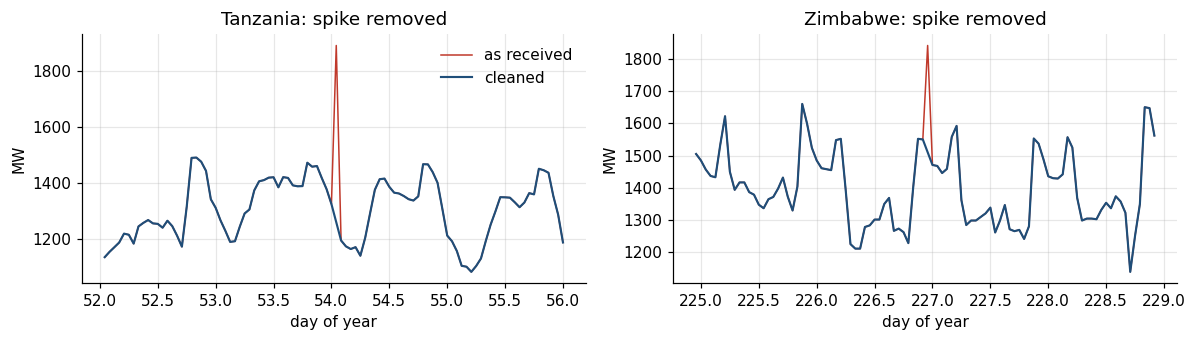

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, c in zip(axes, ['Tanzania', 'Zimbabwe']):
    df = load[c]
    t = int(np.flatnonzero(df.spike.values)[0])
    sl = slice(max(t - 48, 0), t + 48)
    x = np.arange(sl.start, sl.stop) / 24
    ax.plot(x, df.value.iloc[sl], color='#c0392b', lw=1, label='as received')
    ax.plot(x, df['clean'].iloc[sl], color='#1f4e79', lw=1.4, label='cleaned')
    ax.set_title(f"{c}: spike removed"); ax.set_xlabel('day of year'); ax.set_ylabel('MW')
axes[0].legend(frameon=False)
plt.tight_layout()

## 3. Map countries to EPM zones

Each zone takes the profile of its country, normalised to its own annual peak (= 1). The pipeline normalises a whole file by its **overall** maximum, so loads in MW would all be scaled by South Africa's 36 GW. Normalising per country first avoids that.

| Zones | Profile used | Note |
|---|---|---|
| Mozambique_South, _Central, _North | Mozambique | Same national profile for all regions, as in the SAPP data |
| Zimbabwe_East, _West | Zimbabwe | |
| Angola_North, _Central, _South, _East | Angola | |
| DRC | Synthetic national DRC demand (Zenodo record 6569890, SSP2-2.6, 2030, ERA5 weather 2018), shifted from UTC to UTC+1 | Matches SNEL's public distribution (Kinshasa and provinces), see below |
| DRC_South | Near-flat mining load: 90% constant + 10% of the DRC shape | Matches SNEL's HV customers, the Katanga mines |
| Mozal | Near-flat: 0.98 + 0.02 × Mozambique shape | Aluminium smelter at constant load (see the note below) |

The 11 countries with real data and the DRC series enter the day selection. DRC_South and Mozal are linear transforms of series already included, so they're added only when the EPM files are written.

**DRC.** SAPP sent no hourly data for DRC. The forecast's two zones match SNEL's customer segments in its 2024 annual report (*Rapport annuel 2024, DGE*, Table 6):

| EPM zone | Forecast energy 2024 | SNEL figure 2024 |
|---|---|---|
| DRC_South | 9,292 GWh | HV customers (the mines): 9,322 GWh |
| DRC | 7,301 GWh | Distribution: 6,490 GWh (Kinshasa 4,550, provinces 1,940), plus losses |

- **DRC.** It takes the synthetic national series, whose shape is the useful part. Its load factor (0.72) is close to Kinshasa's served load factor in the report (4,550 GWh against a 669.8 MW peak, 0.77). Its weather year is 2018, so on each representative day the value of the same calendar day of 2018 is used. The day-to-day link with 2024 weather is therefore approximate.
- **DRC_South.** Mining load runs almost flat.

**Why not perfectly flat.** `generate_demand.gms` divides by (profile max − profile min)², so a perfectly flat profile breaks the demand computation. Mozal and DRC_South are therefore given a small variation. With Mozal's forecast (energy = peak × 8,760), the resulting demand is still a constant 950 MW.

In [6]:
ZONE_LOAD_SOURCE = {
    'South_Africa': 'South_Africa', 'Lesotho': 'Lesotho', 'Eswatini': 'Eswatini', 'Botswana': 'Botswana',
    'Namibia': 'Namibia', 'Zambia': 'Zambia', 'Tanzania': 'Tanzania', 'Malawi': 'Malawi',
    'Mozambique_South': 'Mozambique', 'Mozambique_Central': 'Mozambique', 'Mozambique_North': 'Mozambique',
    'Zimbabwe_East': 'Zimbabwe', 'Zimbabwe_West': 'Zimbabwe',
    'Angola_North': 'Angola', 'Angola_Central': 'Angola', 'Angola_South': 'Angola', 'Angola_East': 'Angola',
    'DRC': 'DRC', 'DRC_South': 'DRC_mining', 'Mozal': 'Mozal_flat',
}
current_zones = set(pd.read_csv(REF_INPUT / 'load' / 'pDemandProfile.csv').iloc[:, 0])
assert current_zones == set(ZONE_LOAD_SOURCE), current_zones ^ set(ZONE_LOAD_SOURCE)

calendar = load['South_Africa'][['month', 'day', 'hour']].copy()
calendar['hour'] -= 1             # hour ending 1-24 -> hour beginning 0-23, as the pipeline expects
load_norm = pd.DataFrame({c: df['clean'] / df['clean'].max() for c, df in load.items()})

# DRC: synthetic national series (UTC) -> local time UTC+1, same calendar day as 2024 (2018 has no 29 February)
drc = pd.read_csv(DRC_SYNTHETIC, parse_dates=['time']).sort_values('time')
assert len(drc) == 8760
drc_local = np.roll(drc.demand_MW.to_numpy(), 1)
load_norm['DRC'] = drc_local / drc_local.max()

# Near-flat profiles (a perfectly flat profile breaks generate_demand.gms)
mining = DRC_MINING_FLAT_SHARE + (1 - DRC_MINING_FLAT_SHARE) * load_norm['DRC'] / load_norm['DRC'].mean()
EXTRA_PROFILES = {'DRC_mining': mining / mining.max(),
                  'Mozal_flat': 0.98 + 0.02 * load_norm['Mozambique']}
for k, v in EXTRA_PROFILES.items():
    print(f"{k}: load factor {v.mean():.3f}, min {v.min():.3f}, max {v.max():.3f}")
print(f"DRC (synthetic): load factor {load_norm['DRC'].mean():.3f}, min {load_norm['DRC'].min():.3f}")
load_long = pd.concat([calendar.assign(zone=c, value=load_norm[c].round(5)) for c in load_norm], ignore_index=True)
(OUT / 'inputs').mkdir(parents=True, exist_ok=True)
load_long[['zone', 'month', 'day', 'hour', 'value']].to_csv(OUT / 'inputs' / 'load_data.csv', index=False)
print(f"{load_norm.shape[1]} load series written, each with max = {load_norm.max().min():.2f}")

DRC_mining: load factor 0.962, min 0.934, max 1.000
Mozal_flat: load factor 0.994, min 0.987, max 1.000
DRC (synthetic): load factor 0.719, min 0.506


12 load series written, each with max = 1.00


## 4. Solar and wind for the same year

The solar PV and wind capacity factors come from the ERA5 point series of `pre-analysis/climate_years/fetch_climate_years.py`, one site per zone. Using the same year as the load keeps the day-to-day correlation between demand, sun and wind, which representative days are meant to capture.

Two alignments are needed:

- **Time zone.** ERA5 is in UTC, the load is in local time. Angola and western DRC are UTC+1, Tanzania UTC+3, and the rest of SAPP UTC+2.
- **Hour convention.** ERA5 radiation at time *t* is accumulated over the hour ending at *t*. It is shifted one more hour, so that hour 0 means 00:00–01:00 as for the load.

In [7]:
UTC_OFFSET = {z: 2 for z in ['South_Africa', 'Lesotho', 'Eswatini', 'Mozambique', 'Mozambique_South', 'Mozambique_Central',
                             'Mozambique_North', 'Mozal', 'Zimbabwe_East', 'Zimbabwe_West', 'Botswana', 'Namibia',
                             'Zambia', 'Malawi', 'DRC_South']}
UTC_OFFSET.update({z: 1 for z in ['Angola', 'Angola_North', 'Angola_Central', 'Angola_South', 'Angola_East', 'DRC']})
UTC_OFFSET['Tanzania'] = 3

def era5_local(zone):
    # Hourly PV and wind of one zone site, in local time, 365 days x 24 hours, hour beginning 0-23.
    src, year = (ERA5_2024, YEAR) if (ERA5_2024 / f'{zone}.csv.gz').exists() else (ERA5_HIST, 2023)
    d = pd.read_csv(src / f'{zone}.csv.gz', parse_dates=['time'])
    d = d[d.time.dt.year == year].sort_values('time').reset_index(drop=True)
    off = UTC_OFFSET[zone]
    t = pd.date_range(f'{year}-01-01', periods=len(d), freq='h')
    out = pd.DataFrame({'month': t.month, 'day': t.day, 'hour': t.hour,
                        'PV': np.roll(d.PV.to_numpy(), off - 1),      # accumulated over the previous hour
                        'Wind': np.roll(d.Wind.to_numpy(), off)})
    out = out[~((out.month == 2) & (out.day == 29))].reset_index(drop=True)
    return out, year

vre_sites = sorted(UTC_OFFSET)
vre, vre_year = {}, {}
for z in vre_sites:
    vre[z], vre_year[z] = era5_local(z)
years_used = pd.Series(vre_year).value_counts()
print('ERA5 year used:', dict(years_used))
if (years_used.index != YEAR).any():
    print(f'WARNING: {years_used.drop(YEAR, errors="ignore").sum()} site(s) use 2023 because the 2024 download is not complete.')

ERA5 year used: {2024: 22}


To keep the optimisation tractable, the day selection uses one PV and one wind site per country, plus the two DRC zones. That gives 11 load + 15 PV + 15 wind series, and the pipeline adds their pairwise correlations. Profiles for every zone in the current `pVREProfile` are written afterwards from the selected days.

In [8]:
SELECT_SITES = ['South_Africa', 'Lesotho', 'Eswatini', 'Botswana', 'Namibia', 'Zambia', 'Tanzania', 'Malawi',
                'Mozambique_South', 'Mozambique_North', 'Zimbabwe_West', 'Angola_North', 'Angola_South', 'DRC', 'DRC_South']
for tech in ('PV', 'Wind'):
    long = pd.concat([vre[z][['month', 'day', 'hour']].assign(zone=z, value=vre[z][tech].round(5)) for z in SELECT_SITES],
                     ignore_index=True)
    long[['zone', 'month', 'day', 'hour', 'value']].to_csv(OUT / 'inputs' / f'{tech.lower()}_data.csv', index=False)
input_files = {'PV': str(OUT / 'inputs' / 'pv_data.csv'), 'Wind': str(OUT / 'inputs' / 'wind_data.csv'),
               'Load': str(OUT / 'inputs' / 'load_data.csv')}
cf = pd.DataFrame({tech: {z: vre[z][tech].mean() for z in SELECT_SITES} for tech in ('PV', 'Wind')})
cf.T

,South_Africa,Lesotho,Eswatini,Botswana,Namibia,Zambia,Tanzania,Malawi,Mozambique_South,Mozambique_North,Zimbabwe_West,Angola_North,Angola_South,DRC,DRC_South
PV,0.198,0.201,0.155,0.197,0.211,0.195,0.198,0.194,0.163,0.180,0.198,0.162,0.204,0.177,0.192
Wind,0.160,0.097,0.067,0.224,0.182,0.184,0.086,0.099,0.199,0.111,0.132,0.011,0.097,0.020,0.102


### 4.1 Offshore wind sites

The zone sites above are on land, so offshore wind needs its own points. ERA5 also covers the sea: 12 offshore points, 30-50 km from the coast so that the nearest ERA5 cell is over water, were downloaded for 2024 (`pre-analysis/climate_years/zone_sites_sapp_offshore.csv`). They follow the areas of the ESMAP offshore wind studies where available (South Africa, Mozambique, Namibia).

- **Conversion.** ERA5 100 m wind, raised to a 150 m hub with a power law (exponent 0.11, typical over the sea), through a generic 15 MW-class offshore power curve (cut-in 3 m/s, rated 10.6 m/s, cut-out 25 m/s, output proportional to the cube of the speed in between), times 0.9 for wake and availability losses.
- **Zone profile** = mean of the zone's sites. Inland zones with an OffshoreWind row in the current file (Angola_East) and the Angola country zone take the Benguela site.
- As for the other technologies, the profile is rescaled to the current file's annual CF in step 7: ERA5 sets the hour-to-hour shape, the study sets the level. Global Wind Atlas or ESMAP site CFs could replace the current CF as the target.

In [9]:
OFF_CURVE = dict(cut_in=3.0, rated=10.6, cut_out=25.0, shear=0.11, hub=150.0, losses=0.9)

def offshore_cf(raw_csv):
    d = pd.read_csv(raw_csv, parse_dates=['valid_time']).sort_values('valid_time')
    d = d[d.valid_time.dt.year == YEAR]
    v = np.hypot(d.u100, d.v100).to_numpy() * (OFF_CURVE['hub'] / 100) ** OFF_CURVE['shear']
    p = np.clip((v ** 3 - OFF_CURVE['cut_in'] ** 3) / (OFF_CURVE['rated'] ** 3 - OFF_CURVE['cut_in'] ** 3), 0, 1)
    p[v > OFF_CURVE['cut_out']] = 0
    return p * OFF_CURVE['losses'], d.latitude.iloc[0], d.longitude.iloc[0]

off_sites = pd.read_csv(OFFSHORE_SITES)
off_series, off_info = {}, []
for s in off_sites.itertuples():
    f = ERA5_OFFSHORE / f'{s.zone}.csv'
    if not f.exists():
        print(f'missing ERA5 offshore series: {s.zone}'); continue
    p, glat, glon = offshore_cf(f)
    off_series.setdefault(s.epm_zone, []).append(p)
    off_info.append(dict(site=s.zone, epm_zone=s.epm_zone, lat=s.lat, lon=s.lon, ERA5_cell=f'{glat:.2f}, {glon:.2f}', CF=p.mean()))
OFF_ALIAS = {'Angola_East': 'Angola_Central', 'Angola': 'Angola_Central'}
off_local = {}
for z in set(off_series) | set(OFF_ALIAS):
    src = OFF_ALIAS.get(z, z)
    if src not in off_series:
        continue
    t = pd.date_range(f'{YEAR}-01-01', periods=len(off_series[src][0]), freq='h')
    o = pd.DataFrame({'month': t.month, 'day': t.day, 'hour': t.hour,
                      'Wind': np.roll(np.mean(off_series[src], axis=0), UTC_OFFSET[src])})
    off_local[z] = o[~((o.month == 2) & (o.day == 29))].reset_index(drop=True)
pd.DataFrame(off_info).round(3)

,site,epm_zone,lat,lon,ERA5_cell,CF
0,Off_NAM_Luderitz,Namibia,-26.700,14.800,"-26.75, 14.75",0.647
1,Off_NAM_WalvisBay,Namibia,-22.900,14.100,"-23.00, 14.00",0.461
2,Off_AGO_Namibe,Angola_South,-15.500,11.700,"-15.50, 11.75",0.135
3,Off_AGO_Benguela,Angola_Central,-12.300,13.100,"-12.25, 13.00",0.054
4,Off_AGO_Luanda,Angola_North,-8.900,12.850,"-9.00, 12.75",0.078
5,Off_MOZ_Zavora,Mozambique_South,-24.700,35.600,"-24.75, 35.50",0.375
6,Off_MOZ_XaiXai,Mozambique_South,-25.400,33.900,"-25.50, 34.00",0.389
7,Off_ZAF_WesternCape,South_Africa,-32.700,17.500,"-32.75, 17.50",0.517
8,Off_ZAF_EasternCape,South_Africa,-34.300,26.000,"-34.25, 26.00",0.532
9,Off_ZAF_KZN,South_Africa,-29.000,32.400,"-29.00, 32.50",0.541


## 5. Run the representative-days pipeline

The pipeline runs twice on the same inputs:

- **default**: the pipeline as before, with special days for minimum PV, minimum wind and maximum load (system-wide cluster) in each season, plus 2 optimised days per season;
- **peak days**: the same, with `peak_load_days=True`, which adds the actual peak day of each country;
- **16 days**: a smaller variant for the aggregated model, see section 10.

The first two isolate the effect of the correction. Each run takes about 30 minutes; with `REUSE_RUNS = True` the selection saved by a previous run (`repr_days.csv`, `peak_load_days.csv`) is read back instead.

In [10]:
common = dict(seasons_map=SEASONS, input_files=input_files, n_representative_days=N_REPR_DAYS, year_label=YEAR,
              gams_main_file=str(BASE / 'gams' / 'OptimizationModelZone.gms'), verbose=False)
RUNS = {
    'default': dict(),
    'peak days': dict(peak_load_days=True),
    '16 days': dict(n_representative_days=3, special_day_features=('Load',), time_limit=1200),   # section 10; 20 min per season
}
res = {}
for label, opts in RUNS.items():
    run_dir = OUT / f"run_{label.replace(' ', '_')}"
    flag = opts.get('peak_load_days', False)
    if REUSE_RUNS and (run_dir / 'repr_days.csv').exists() and (not flag or (run_dir / 'peak_load_days.csv').exists()):
        res[label] = {'repr_days': pd.read_csv(run_dir / 'repr_days.csv'),
                      'peak_load_days': pd.read_csv(run_dir / 'peak_load_days.csv') if flag else None}
        print(f'{label}: selection read from {run_dir.name}/repr_days.csv (REUSE_RUNS)')
    else:
        res[label] = run_representative_days_pipeline(output_dir=run_dir, **{**common, **opts})
    rd = res[label]['repr_days']
    print(f"{label:10s}: {len(rd)} days, weight {rd.weight.sum():.0f}, by season {rd.groupby('season').size().to_dict()}")

default: selection read from run_default/repr_days.csv (REUSE_RUNS)
default   : 20 days, weight 365, by season {'Q1': 5, 'Q2': 5, 'Q3': 5, 'Q4': 5}
peak days: selection read from run_peak_days/repr_days.csv (REUSE_RUNS)
peak days : 31 days, weight 365, by season {'Q1': 8, 'Q2': 8, 'Q3': 9, 'Q4': 6}


Representative year 2024


'Annual capacity factor (%):'

tech,zone,PV,Wind,Load
0,Angola,NaN,NaN,0.756
1,Angola_North,0.162,0.011,NaN
2,Angola_South,0.204,0.097,NaN
3,Botswana,0.197,0.224,0.701
4,DRC,0.177,0.020,0.719
5,DRC_South,0.192,0.102,NaN
6,Eswatini,0.155,0.067,0.635
7,Lesotho,0.201,0.097,0.585
8,Malawi,0.194,0.099,0.718
9,Mozambique,NaN,NaN,0.723


File saved at: C:\Users\wb590499\Documents\Projects\EPM\pre-analysis\representative_days\output\sapp_2024\run_16_days\data_formatted_optim.csv
File saved to: gams\bins_settings_10.csv
Launch GAMS code
Command to execute: gams C:\Users\wb590499\Documents\Projects\EPM\pre-analysis\representative_days\gams\OptimizationModelZone.gms --data C:\Users\wb590499\Documents\Projects\EPM\pre-analysis\representative_days\output\sapp_2024\run_16_days\data_formatted_optim.csv --settings C:\Users\wb590499\Documents\Projects\EPM\pre-analysis\representative_days\gams\bins_settings_10.csv --N 3 reslim=1200


End GAMS code


C:\Users\wb590499\.conda\envs\epm_env\Lib\site-packages\gams\transfer\containers\_container.py:73: UserWarning: The GAMS version (50.1.0) differs from the API version (51.4.0).
  ws = GamsWorkspace()


Number of days: 16
Total weight: 365
season
Q1   90.000
Q2   91.000
Q3   92.000
Q4   92.000
Name: weight, dtype: float64
pHours file saved at: C:\Users\wb590499\Documents\Projects\EPM\pre-analysis\representative_days\output\sapp_2024\run_16_days\pHours.csv
Number of hours: 365
VRE Profile file saved at: C:\Users\wb590499\Documents\Projects\EPM\pre-analysis\representative_days\output\sapp_2024\run_16_days\pVREProfile.csv
pDemandProfile file saved at: C:\Users\wb590499\Documents\Projects\EPM\pre-analysis\representative_days\output\sapp_2024\run_16_days\pDemandProfile.csv


16 days   : 16 days, weight 365, by season {'Q1': 4, 'Q2': 4, 'Q3': 4, 'Q4': 4}


In [11]:
# Calendar date of each (season, day index)
dates = pd.DataFrame({'date': pd.date_range(f'{YEAR}-01-01', f'{YEAR}-12-31')})
dates = dates[~((dates.date.dt.month == 2) & (dates.date.dt.day == 29))]
dates['season'] = 'Q' + dates.date.dt.month.map(SEASONS).astype(str)
dates['day'] = dates.groupby('season').cumcount() + 1
date_of = dates.set_index(['season', 'day']).date

def describe_days(rd):
    rd = rd.copy()
    rd['date'] = [date_of[(s, d)].strftime('%d %b') for s, d in zip(rd.season, rd.day)]
    return rd[['season', 'daytype', 'date', 'weight', 'rule']].sort_values(['season', 'daytype']).reset_index(drop=True)

repr_peak = describe_days(res['peak days']['repr_days'])
repr_peak

,season,daytype,date,weight,rule
0,Q1,d1,16 Jan,4.000,min_PV
1,Q1,d2,18 Mar,29.000,representative
2,Q1,d3,02 Feb,37.000,representative
3,Q1,d4,22 Feb,1.000,peak_Load_Zambia
4,Q1,d5,10 Mar,1.000,peak_Load_DRC
5,Q1,d6,06 Mar,1.000,peak_Load_Eswatini
6,Q1,d7,04 Feb,14.000,min_Wind
7,Q1,d8,15 Feb,3.000,max_Load
8,Q2,d1,31 May,42.000,representative
9,Q2,d2,20 Apr,33.000,representative


In [12]:
pk = res['peak days']['peak_load_days'].copy()
pk['country'] = pk.series.str.replace('Load_', '', regex=False)
pk['date'] = [date_of[(f'Q{s}', d)].strftime('%d %b') for s, d in zip(pk.season, pk.day)]
pk[['country', 'date', 'hour', 'action']]

,country,date,hour,action
0,Angola,02 May,20,"added (weight 1, removed from optimisation pool)"
1,Botswana,04 Jun,18,"added (weight 1, removed from optimisation pool)"
2,DRC,10 Mar,17,"added (weight 1, taken from special day min_Wind)"
3,Eswatini,06 Mar,18,"added (weight 1, removed from optimisation pool)"
4,Lesotho,05 Jul,9,"added (weight 1, taken from special day min_PV)"
5,Malawi,18 Sep,18,"added (weight 1, removed from optimisation pool)"
6,Mozambique,09 Sep,18,"added (weight 1, removed from optimisation pool)"
7,Namibia,04 Jun,19,already a selected day
8,South_Africa,04 Jul,18,"added (weight 1, removed from optimisation pool)"
9,Tanzania,26 Nov,19,"added (weight 1, taken from special day max_Load)"


Each country's peak day is now one of the selected days. Countries that peak on the same day share it, and a peak day that was already selected is not added twice. When the peak day belongs to a cluster already represented by a special day, one day of weight moves from that special day to the peak day, so the season keeps its number of days.

## 6. Check the result

### 6.1 Profile maximum, the main correction

The model peak of each zone equals the profile maximum × the forecast peak. Values below 1 under-state the peak.

In [13]:
def hourly_by_day(series, rd):
    # series indexed like `calendar` (365 x 24) -> array (n_days, 24) for the selected days
    M = np.asarray(series, dtype=float).reshape(365, 24)
    idx = [dates.index.get_loc(dates[(dates.season == s) & (dates.day == d)].index[0]) for s, d in zip(rd.season, rd.day)]
    return M[idx]

cur_prof = pd.read_csv(REF_INPUT / 'load' / 'pDemandProfile.csv')
cur_prof.columns = ['zone', 'q', 'd'] + [f't{i}' for i in range(1, 25)]
cur_hours = pd.read_csv(REF_INPUT / 'pHours.csv', encoding='utf-8-sig')
tcols = [f't{i}' for i in range(1, 25)]

def weighted_lf(P, w):
    return float((P * w[:, None]).sum() / (w.sum() * 24) / P.max())

rows = []
for c in load_norm:
    zone = next(z for z, s in ZONE_LOAD_SOURCE.items() if s == c)
    cp = cur_prof[cur_prof.zone == zone].merge(cur_hours, on=['q', 'd'], suffixes=('', '_w'))
    row = dict(country=c, current=cp[tcols].to_numpy().max())
    for label in res:
        rd = res[label]['repr_days']
        row[label] = hourly_by_day(load_norm[c], rd).max()
    w = res['peak days']['repr_days'].weight.to_numpy()
    row.update(LF_observed=load_stats['load_factor'].get(c, load_norm[c].mean()),   # DRC: synthetic series
               LF_current=float((cp[tcols].to_numpy() * cp[[f'{t}_w' for t in tcols]].to_numpy()).sum() / (8760 * cp[tcols].to_numpy().max())),
               LF_new=weighted_lf(hourly_by_day(load_norm[c], res['peak days']['repr_days']), w))
    rows.append(row)
peak_check = pd.DataFrame(rows).set_index('country')
below = lambda col: ', '.join(f"{c} {v:.2f}" for c, v in peak_check[col].items() if v < 0.995) or 'none'
print(f"Profile max below 1 - current file: {below('current')}")
print(f"Profile max below 1 - default pipeline: {below('default')}")
print(f"Profile max below 1 - with peak days: {below('peak days')}")
gap = lambda col: (peak_check[col] - peak_check.LF_observed).abs().mean()
print(f"Mean gap to the observed load factor: current {gap('LF_current'):.3f}, new {gap('LF_new'):.3f}")
peak_check.style.format('{:.3f}').background_gradient(subset=['current', 'default', 'peak days'], cmap='RdYlGn', vmin=0.8, vmax=1.0)

Profile max below 1 - current file: Eswatini 0.85, Lesotho 0.88, Malawi 0.95, Mozambique 0.97, Namibia 0.95, Zimbabwe 0.81, Zambia 0.88, Tanzania 0.93, South_Africa 0.96, Botswana 0.92
Profile max below 1 - default pipeline: Eswatini 0.94, Lesotho 0.94, Malawi 0.96, Mozambique 0.96, Namibia 0.99, Zimbabwe 0.92, Zambia 0.94, Tanzania 0.96, South_Africa 0.98, Angola 0.99, Botswana 0.94, DRC 0.99
Profile max below 1 - with peak days: none
Mean gap to the observed load factor: current 0.063, new 0.008


,current,default,peak days,16 days,LF_observed,LF_current,LF_new
country,,,,,,,
Eswatini,0.850,0.937,1.000,0.937,0.635,0.747,0.603
Lesotho,0.880,0.944,1.000,0.937,0.585,0.664,0.575
Malawi,0.950,0.959,1.000,0.967,0.718,0.755,0.726
Mozambique,0.970,0.961,1.000,0.961,0.723,0.749,0.718
Namibia,0.950,0.988,1.000,0.981,0.727,0.765,0.731
Zimbabwe,0.810,0.923,1.000,0.904,0.700,0.863,0.702
Zambia,0.880,0.943,1.000,0.943,0.693,0.788,0.704
Tanzania,0.930,0.958,1.000,0.929,0.700,0.751,0.710
South_Africa,0.960,0.984,1.000,0.963,0.759,0.791,0.757


- **Profile maximum.** With the correction, every country's profile reaches 1, so EPM keeps the forecast peak of each zone. The default pipeline, with only the system-wide `max_Load` special day, still leaves several countries below 1.
- **Load factor.** `LF_new` is the load factor of the representative profile (energy ÷ peak × 8,760 hours). Compare it with the observed 2024 value: the current profiles are flatter than the observed load, which under-states how peaky demand is.

### 6.2 Load duration curves: full year against the representative days

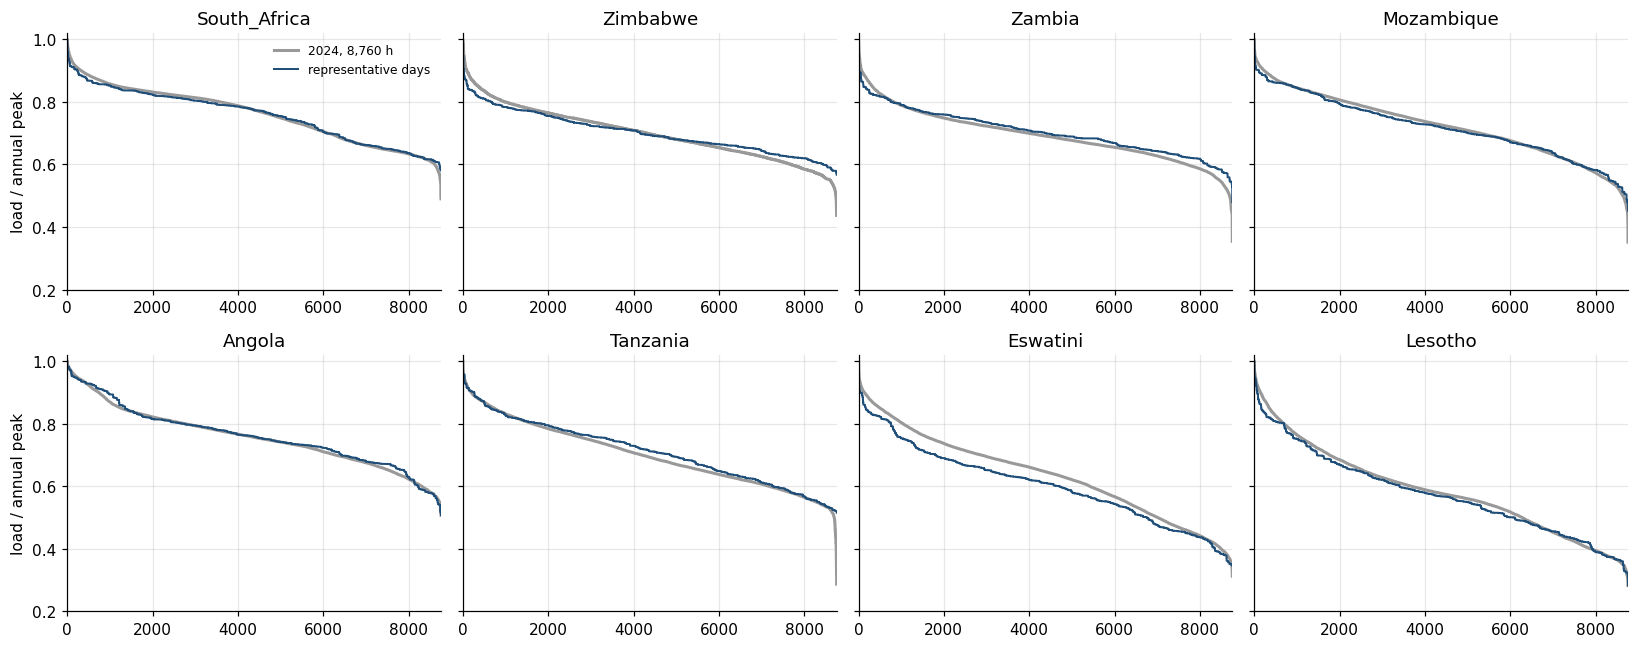

In [14]:
rd = res['peak days']['repr_days']; w = rd.weight.to_numpy()
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for ax, c in zip(axes.ravel(), ['South_Africa', 'Zimbabwe', 'Zambia', 'Mozambique', 'Angola', 'Tanzania', 'Eswatini', 'Lesotho']):
    full = np.sort(load_norm[c].to_numpy())[::-1]
    P = hourly_by_day(load_norm[c], rd)
    vals = P.ravel(); wt = np.repeat(w, 24)
    o = np.argsort(vals)[::-1]
    ax.plot(np.arange(1, 8761), full, color='#999999', lw=2, label='2024, 8,760 h')
    ax.step(np.cumsum(wt[o]), vals[o], where='post', color='#1f4e79', lw=1.3, label='representative days')
    ax.set_title(c); ax.set_xlim(0, 8760); ax.set_ylim(0.2, 1.02)
axes[0, 0].legend(frameon=False, fontsize=8); axes[0, 0].set_ylabel('load / annual peak'); axes[1, 0].set_ylabel('load / annual peak')
plt.tight_layout()

### 6.3 Average day by season

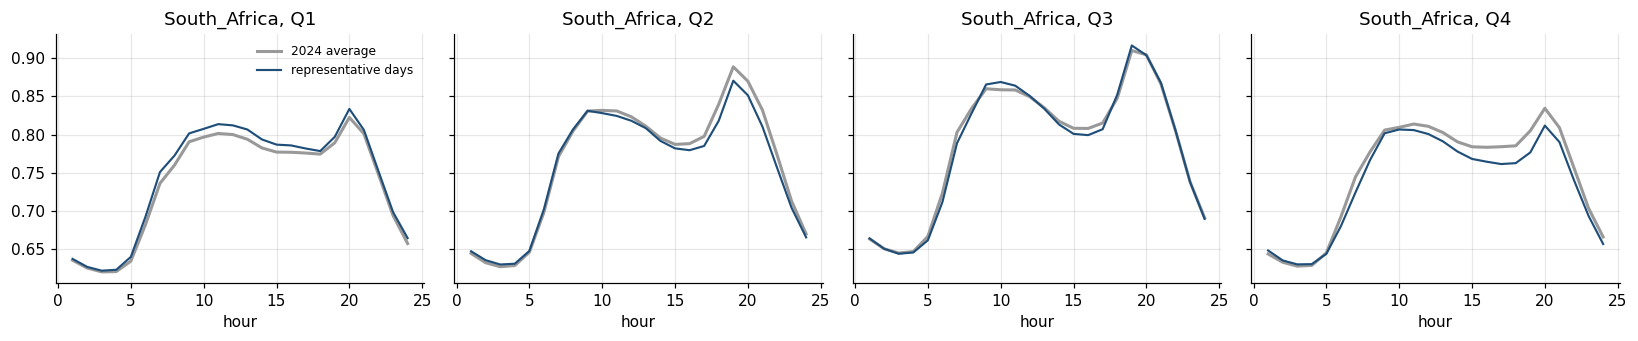

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
c = 'South_Africa'
M = load_norm[c].to_numpy().reshape(365, 24)
P = hourly_by_day(load_norm[c], rd)
for ax, q in zip(axes, ['Q1', 'Q2', 'Q3', 'Q4']):
    m = (dates.season == q).to_numpy()
    sel = (rd.season == q).to_numpy()
    ax.plot(range(1, 25), M[m].mean(0), color='#999999', lw=2, label='2024 average')
    ax.plot(range(1, 25), (P[sel] * w[sel, None]).sum(0) / w[sel].sum(), color='#1f4e79', lw=1.4, label='representative days')
    ax.set_title(f'{c}, {q}'); ax.set_xlabel('hour')
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

## 7. Write the EPM files

The three files must be replaced **together**, because the day labels (`d1`, `d2`...) refer to different calendar days than in the current files.

- **`pHours.csv`**: the weight of each selected day (days per year it stands for).
- **`pDemandProfile.csv`**: the normalised load of each zone on the selected days, with the country-to-zone mapping of step 3.
- **`pVREProfile.csv`**: every (zone, technology) pair of the current file, from the ERA5 series of that zone on the selected days.
  - Each profile is rescaled so that its annual capacity factor equals the current file's, capped at 1. The current file reflects the resource assessment of the study, while ERA5 at a zone centroid gives the day-to-day pattern only.
  - CSP uses the PV series shape. Offshore wind uses the ERA5 offshore sites of step 4.1.
- **`pVREgenProfile.csv`**: Ruacana run-of-river has one value per season, which is repeated on the new days.
- **`pTradePrice.csv`**: the average of the current days of each season, repeated on the new days. The current prices are almost identical across days, and external exchange is off in this dataset.

In [16]:
rd = res['peak days']['repr_days'].sort_values(['season', 'daytype']).reset_index(drop=True)
w = rd.weight.to_numpy()

# pHours
ph = rd[['season', 'daytype']].rename(columns={'season': 'q', 'daytype': 'd'})
for t in tcols: ph[t] = rd.weight.astype(int)
ph.to_csv(EPM_OUT / 'pHours.csv', index=False, encoding='utf-8-sig')
print('days per season:', ph.groupby('q')['t1'].sum().to_dict(), '| total', int(ph['t1'].sum()))

# pDemandProfile (same header as the current file)
rows = []
for zone, src in ZONE_LOAD_SOURCE.items():
    P = hourly_by_day(EXTRA_PROFILES[src] if src in EXTRA_PROFILES else load_norm[src], rd)
    for (q, d), vals in zip(rd[['season', 'daytype']].values, P):
        rows.append([zone, q, d] + list(np.round(vals, 4)))
pdp = pd.DataFrame(rows, columns=['Zone', 'm', 'd'] + tcols)
pdp.to_csv(EPM_OUT / 'pDemandProfile.csv', index=False)
print('pDemandProfile:', pdp.Zone.nunique(), 'zones, max per zone:', pdp.groupby('Zone')[tcols].max().max(1).round(3).unique())

days per season: {'Q1': 90, 'Q2': 91, 'Q3': 92, 'Q4': 92} | total 365


pDemandProfile: 20 zones, max per zone: [1.]


In [17]:
cur_vre = pd.read_csv(REF_INPUT / 'supply' / 'pVREProfile.csv')
cur_vre = cur_vre.merge(cur_hours, on=['q', 'd'], suffixes=('', '_w'))
RESOURCE = {'PV': 'PV', 'CSPPlant': 'PV', 'OnshoreWind': 'Wind', 'OffshoreWind': 'Wind'}
SITE_ALIAS = {'Zimbabwe': 'Zimbabwe_West'}

def scale_to(P, w, target):
    # Factor k so that the weighted mean of min(k*P, 1) equals target (bisection).
    if target <= 0 or P.max() <= 0:
        return 0.0
    lo, hi = 0.0, 50.0
    for _ in range(60):
        k = (lo + hi) / 2
        m = (np.minimum(k * P, 1) * w[:, None]).sum() / (w.sum() * 24)
        lo, hi = (k, hi) if m < target else (lo, k)
    return k

rows, vre_rows = [], []
for (zone, tech), g in cur_vre.groupby(['zone', 'tech']):
    target = float((g[tcols].to_numpy() * g[[f"{t}_w" for t in tcols]].to_numpy()).sum() / 8760)
    site = SITE_ALIAS.get(zone, zone)
    offshore = tech == 'OffshoreWind' and zone in off_local
    P = hourly_by_day(off_local[zone]['Wind'] if offshore else vre[site][RESOURCE[tech]], rd)
    raw_cf = float((P * w[:, None]).sum() / (w.sum() * 24))
    k = scale_to(P, w, target)
    Ps = np.minimum(k * P, 1)
    for (q, d), vals in zip(rd[['season', 'daytype']].values, Ps):
        vre_rows.append([zone, tech, q, d] + list(np.round(vals, 4)))
    note = []
    if offshore:
        note.append('ERA5 offshore: ' + ', '.join(off_sites.loc[off_sites.epm_zone == OFF_ALIAS.get(zone, zone), 'zone']))
    elif tech == 'OffshoreWind':
        note.append('no offshore site: onshore wind shape at the zone site')
    if tech == 'CSPPlant': note.append('PV shape')
    if site != zone and not offshore: note.append(f'site {site}')
    if k > 2.5 or (0 < k < 0.4): note.append('large rescaling: check the site')
    rows.append(dict(zone=zone, tech=tech, target_CF=target, ERA5_CF=raw_cf, scale=k,
                     new_CF=float((Ps * w[:, None]).sum() / (w.sum() * 24)), note='; '.join(note)))
pvre = pd.DataFrame(vre_rows, columns=['zone', 'tech', 'q', 'd'] + tcols)
pvre.to_csv(EPM_OUT / 'pVREProfile.csv', index=False)
vre_check = pd.DataFrame(rows)
vre_check.style.format({'target_CF': '{:.3f}', 'ERA5_CF': '{:.3f}', 'scale': '{:.2f}', 'new_CF': '{:.3f}'}).hide(axis='index')

zone,tech,target_CF,ERA5_CF,scale,new_CF,note
Angola,CSPPlant,0.256,0.184,1.39,0.256,PV shape
Angola,OffshoreWind,0.066,0.056,1.18,0.066,ERA5 offshore: Off_AGO_Benguela
Angola,OnshoreWind,0.185,0.021,11.97,0.185,large rescaling: check the site
Angola,PV,0.187,0.184,1.01,0.187,
Angola_Central,OffshoreWind,0.066,0.056,1.18,0.066,ERA5 offshore: Off_AGO_Benguela
Angola_Central,OnshoreWind,0.185,0.018,15.20,0.185,large rescaling: check the site
Angola_Central,PV,0.187,0.184,1.01,0.187,
Angola_East,OffshoreWind,0.066,0.056,1.18,0.066,ERA5 offshore: Off_AGO_Benguela
Angola_East,OnshoreWind,0.185,0.053,3.58,0.185,large rescaling: check the site
Angola_East,PV,0.187,0.188,0.99,0.187,


In [18]:
# pVREgenProfile: one value per plant and season, repeated on the new days
gp = pd.read_csv(REF_INPUT / 'supply' / 'pVREgenProfile.csv')
per_season = gp.groupby(['gen', 'q'])[tcols].mean()
gp_new = rd[['season', 'daytype']].rename(columns={'season': 'q', 'daytype': 'd'}).merge(per_season.reset_index(), on='q')
gp_new[['gen', 'q', 'd'] + tcols].to_csv(EPM_OUT / 'pVREgenProfile.csv', index=False)

# pTradePrice: average over the current days of each season, repeated on the new days
tp = pd.read_csv(REF_INPUT / 'trade' / 'pTradePrice.csv', header=None, skiprows=1)
tp.columns = ['zext', 'q', 'd', 'y'] + [f't{i:02d}' for i in range(1, 25)]
tp_mean = tp.groupby(['zext', 'q', 'y'])[[f't{i:02d}' for i in range(1, 25)]].mean().reset_index()
tp_new = tp_mean.merge(rd[['season', 'daytype']].rename(columns={'season': 'q', 'daytype': 'd'}), on='q')
tp_new = tp_new[['zext', 'q', 'd', 'y'] + [f't{i:02d}' for i in range(1, 25)]].sort_values(['zext', 'y', 'q', 'd'])
with open(EPM_OUT / 'pTradePrice.csv', 'w', newline='') as f:
    f.write(',,,,' + ','.join(f't{i:02d}' for i in range(1, 25)) + '\n')
    tp_new.to_csv(f, header=False, index=False)
print('Written:', sorted(p.name for p in EPM_OUT.glob('*.csv')))

Written: ['pDemandProfile.csv', 'pHours.csv', 'pTradePrice.csv', 'pVREProfile.csv', 'pVREgenProfile.csv']


## 8. Effect on the model's hourly demand

The model's hourly demand is recomputed the way `generate_demand.gms` does: profile × forecast peak, plus the correction that matches the annual energy. It is computed for 2025–2055 from the current forecast (`pDemandForecast_sapp_poolplan_v5_mozalout.csv`), first with the current profiles, then with the new ones.

In [19]:
fc = pd.read_csv(EPM_INPUT / 'load' / 'pDemandForecast_sapp_poolplan_v5_mozalout.csv')
fc = fc.melt(id_vars=['z', 'type'], var_name='y', value_name='v')
fc['y'] = fc.y.astype(int)
fc = fc[(fc.y >= 2025) & (fc.y <= 2055)].pivot_table(index=['z', 'y'], columns='type', values='v').reset_index()

def model_demand(profile, hours, zone, energy_GWh, peak_MW):
    g = profile[profile.zone == zone].merge(hours, on=['q', 'd'], suffixes=('', '_w'))
    p = g[tcols].to_numpy(); wt = g[[f'{t}_w' for t in tcols]].to_numpy()
    pmax = p.max(); S = (p * wt).sum(); A = ((pmax - p) * wt).sum()
    k = (energy_GWh * 1e3 - peak_MW * S) / A if A > 0 else 0.0
    return p * peak_MW + k * (pmax - p)

new_prof = pdp.rename(columns={'Zone': 'zone', 'm': 'q'})
new_hours = ph
out = []
for _, x in fc[fc.Energy > 1].iterrows():
    for label, prof, hrs in (('current', cur_prof, cur_hours), ('new', new_prof, new_hours)):
        h = model_demand(prof, hrs, x.z, x.Energy, x.Peak)
        out.append(dict(zone=x.z, y=x.y, profile=label, peak_ratio=h.max() / x.Peak, min_MW=h.min()))
dem = pd.DataFrame(out)
summary = dem.groupby(['zone', 'profile']).agg(model_peak_vs_forecast=('peak_ratio', 'min'), lowest_hour_MW=('min_MW', 'min')).unstack('profile')
summary.columns = [f'{a} ({b})' for a, b in summary.columns]
for label in ('current', 'new'):
    neg = summary[f'lowest_hour_MW ({label})']
    print(f"Zones with negative hourly demand, {label} profiles: " +
          (', '.join(f"{z} ({v:,.0f} MW)" for z, v in neg[neg < 0].items()) or 'none'))
summary.style.format('{:.2f}', subset=[c for c in summary.columns if 'peak' in c]).format('{:,.0f}', subset=[c for c in summary.columns if 'lowest' in c])

Zones with negative hourly demand, current profiles: DRC (-4,306 MW), Mozambique_Central (-91 MW), Mozambique_North (-258 MW), Mozambique_South (-39 MW)
Zones with negative hourly demand, new profiles: DRC (-1,682 MW), Mozambique_Central (-73 MW), Mozambique_North (-336 MW)


,model_peak_vs_forecast (current),model_peak_vs_forecast (new),lowest_hour_MW (current),lowest_hour_MW (new)
zone,,,,
Angola_Central,0.97,1.00,130,126
Angola_East,0.95,1.00,28,25
Angola_North,1.03,1.00,586,780
Angola_South,1.03,1.00,62,59
Botswana,0.92,1.00,304,331
DRC,1.00,1.00,"-4,306","-1,682"
DRC_South,1.00,1.00,232,608
Eswatini,0.85,1.00,98,104
Lesotho,0.88,1.00,70,62


- **Model peak.** With the new profiles, the model peak equals the forecast peak in every zone (ratio 1.00).
- **Negative hours.** Where they remain, they come from the **forecast**, not from the profile: its peak is too high for its energy. The load factor is 0.23–0.37 in Mozambique_North, 0.42–0.69 in Mozambique_Central and 0.31–0.34 in DRC, against about 0.7 in the observed data. No profile shape can turn such a forecast into positive demand in every hour.
- **Corrections.** The Mozambique zone peaks are corrected in section 8.2, using EDM's 2024 annual report. The DRC energies are corrected in section 8.3, using SNEL's 2024 annual report. Both go into one corrected forecast file.

### 8.2 Mozambique zone peaks from the EDM Annual Statistical Report 2024

Source: Electricidade de Moçambique, *Relatório Anual de Estatística / Annual Statistical Report 2024*:

- integrated peak: page 30, Table 6 and Figure 11;
- daily maxima of each system: Tables 7–9, pages 32–34;
- registered peak of each delivery point: pages 18–21;
- energy by region: Table 11;
- special customers: Table 12.

Three findings:

1. **The SAPP hourly series is EDM's integrated system.** Its maximum matches the integrated peak in the report, in size and date (checked below).
2. **The forecast's zone peaks are sums of substation peaks.** Summing the registered peaks of the delivery points reproduces the 2024 forecast peaks with the same factor of 1.28 in each zone (table below). Substations peak at different times, so their sum (1,633 MW) is 44% above the integrated peak (1,137 MW). The extra 1.28 brings the zone peaks to almost twice the real ones. That is why the forecast's load factors are so low.
3. **Zambézia is counted in different zones for energy and for peak.** The peaks only reproduce with Zambézia in North. The energies match EDM's regions only with Zambézia in Central, where EDM's Central region puts it. Below, Zambézia is in Central for both.

In [20]:
# Registered peak of each delivery point in 2024 (MW), EDM report pages 18-21 (non-coincident)
SUBSTATION_PEAKS = {
    'Mozambique_South':   {'Maputo City': [26.1, 26.5, 21.7, 42.9, 14.8, 23.1, 20.9, 26.0, 18.3, 32.1, 27.36, 16.1, 18.0, 8.9],
                           'Maputo Province': [7.9, 22.51, 10.9, 64.54, 14.1, 19.5, 27.8, 42.8, 6.9, 3.23, 53.1, 4.1],
                           'Gaza': [12.6, 21.86, 22, 0.7, 32.5, 16.4], 'Inhambane': [9.3, 24.7, 9.6]},
    'Mozambique_Central': {'Tete': [101.3, 17.9, 32.9, 3.8, 16.9, 5.8], 'Manica': [5.4, 44.1, 6.7, 4.4, 0.9, 6.2, 1.5, 3.2],
                           'Sofala': [8.3, 35.8, 107.3, 6.1, 0.0, 3.3, 0.0], 'Zambezia': [39.8, 6.03, 1.6, 40.8, 19.44, 9.01, 10.8]},
    'Mozambique_North':   {'Nampula, Niassa, Cabo Delgado': [24.2, 1.3, 10.8, 3.8, 13.1, 5.9, 0.43, 5.30, 5.00, 52.5, 177.2, 4.56, 32.2, 7.6]},
}
sub = {z: {p: sum(v) for p, v in d.items()} for z, d in SUBSTATION_PEAKS.items()}

# 1. Hourly data against the report's integrated peak (1,137 MW on 9 September 2024)
moz = load_raw['Mozambique']
i = moz.value.idxmax()
print(f"Hourly data: max {moz.value.max():,.1f} MW on {int(moz.month[i]):02d}-{int(moz.day[i]):02d}, hour ending {int(moz.hour[i])}:00"
      " | report: 1,137 MW on 09-09-2024")

# 2. How the forecast's 2024 peaks were built (Zambezia counted in North, as in the forecast)
fc_all = pd.read_csv(EPM_INPUT / 'load' / 'pDemandForecast_sapp_poolplan_v5_mozalout.csv')
fc_all = fc_all.melt(id_vars=['z', 'type'], var_name='y', value_name='v').astype({'y': int})
fc24 = fc_all[fc_all.y == 2024].pivot_table(index='z', columns='type', values='v')
sums_as_forecast = {'Mozambique_South': sum(sub['Mozambique_South'].values()),
                    'Mozambique_Central': sum(v for p, v in sub['Mozambique_Central'].items() if p != 'Zambezia'),
                    'Mozambique_North': sub['Mozambique_North']['Nampula, Niassa, Cabo Delgado'] + sub['Mozambique_Central']['Zambezia']}
origin = pd.DataFrame({'sum of substation peaks (MW)': sums_as_forecast,
                       'forecast peak 2024 (MW)': fc24.loc[list(sums_as_forecast), 'Peak']})
origin['ratio'] = origin.iloc[:, 1] / origin.iloc[:, 0]
origin.round(2)

Hourly data: max 1,136.6 MW on 09-09, hour ending 19:00 | report: 1,137 MW on 09-09-2024


,sum of substation peaks (MW),forecast peak 2024 (MW),ratio
Mozambique_South,749.800,957.650,1.280
Mozambique_Central,411.800,526.590,1.280
Mozambique_North,471.370,602.760,1.280


**Peaks that occur together.** On the day of the national peak, 9 September 2024, the daily maxima of EDM's three systems were:

| System | Daily maximum, 9 Sep 2024 |
|---|---|
| South | 649 MW |
| Central (Manica, Sofala) | 133 MW |
| Centre-North & Tete | 367 MW |

These add up to 1,149 MW, close to the integrated 1,137 MW, so they occur almost together.

The Centre-North & Tete system is split in proportion to its substation peaks: the Tete and Zambézia part goes to Central, the rest to North. The three values are then scaled to 1,137 MW. Each zone's load factor is its 2024 energy (Table 11, including losses, plus the special customers of Table 12) ÷ (coincident peak × 8,784 hours).

The corrected forecast keeps the original energy in every year and sets **peak = energy ÷ (zone load factor × 8,760)**. The profile shape is the same in every model year, so the load factor is held constant too.

In [21]:
SYSTEM_PEAK_9SEP = {'South': 649, 'Central (Manica, Sofala)': 133, 'Centre-North & Tete': 367}   # Tables 7-9
tz = sub['Mozambique_Central']['Tete'] + sub['Mozambique_Central']['Zambezia']
share_tz = tz / (tz + sub['Mozambique_North']['Nampula, Niassa, Cabo Delgado'])
coincident = {'Mozambique_South': SYSTEM_PEAK_9SEP['South'],
              'Mozambique_Central': SYSTEM_PEAK_9SEP['Central (Manica, Sofala)'] + SYSTEM_PEAK_9SEP['Centre-North & Tete'] * share_tz,
              'Mozambique_North': SYSTEM_PEAK_9SEP['Centre-North & Tete'] * (1 - share_tz)}
scale = 1137 / sum(coincident.values())
ENERGY_2024 = {'Mozambique_South': 3650 + 78.182, 'Mozambique_Central': 1494 + 467.512, 'Mozambique_North': 918 + 313.330}  # GWh
moz_lf = pd.DataFrame({'coincident peak 2024 (MW)': {z: v * scale for z, v in coincident.items()}, 'energy 2024 (GWh)': ENERGY_2024})
moz_lf['load factor'] = (moz_lf['energy 2024 (GWh)'] * 1e3 / (moz_lf['coincident peak 2024 (MW)'] * 8784)).round(3)
print(f"Tete + Zambezia share of the Centre-North & Tete system: {share_tz:.2f}; scaling to 1,137 MW: {scale:.3f}")
moz_lf.round(3)

Tete + Zambezia share of the Centre-North & Tete system: 0.47; scaling to 1,137 MW: 0.990


,coincident peak 2024 (MW),energy 2024 (GWh),load factor
Mozambique_South,642.222,3728.182,0.661
Mozambique_Central,302.631,1961.512,0.738
Mozambique_North,192.147,1231.330,0.730


In [22]:
NEW_FORECAST = EPM_INPUT / 'load' / 'pDemandForecast_sapp_poolplan_v5_mozalout_corrected.csv'
moz_fix = fc[fc.z.str.startswith('Mozambique')].copy()
moz_fix['Peak_corrected'] = moz_fix.Energy * 1e3 / (moz_fix.z.map(moz_lf['load factor']) * 8760)

# The corrected forecast file must hold the same values
written = pd.read_csv(NEW_FORECAST).melt(id_vars=['z', 'type'], var_name='y', value_name='v').astype({'y': int})
written = written[(written.type == 'Peak')].set_index(['z', 'y']).v
gap = (moz_fix.set_index(['z', 'y']).Peak_corrected - written.reindex(moz_fix.set_index(['z', 'y']).index)).abs().max()
print(f"{NEW_FORECAST.name}: largest difference with this computation {gap:.4f} MW")

rows = []
for _, x in moz_fix.iterrows():
    for label, peak in (('forecast', x.Peak), ('corrected', x.Peak_corrected)):
        h = model_demand(new_prof, new_hours, x.z, x.Energy, peak)
        rows.append(dict(zone=x.z, y=x.y, peaks=label, peak_MW=peak, lowest_hour_MW=h.min()))
res_fix = pd.DataFrame(rows)
low = res_fix.groupby(['zone', 'peaks']).lowest_hour_MW.min().unstack('peaks')[['forecast', 'corrected']]
print('\nLowest hourly demand over 2025-2055 with the new profiles (MW):')
print(low.round(0).to_string())
res_fix[res_fix.y.isin([2025, 2030, 2040, 2050, 2055])].pivot_table(index='y', columns=['peaks', 'zone'], values='peak_MW').round(0)

pDemandForecast_sapp_poolplan_v5_mozalout_corrected.csv: largest difference with this computation 0.0000 MW



Lowest hourly demand over 2025-2055 with the new profiles (MW):
peaks               forecast  corrected
zone                                   
Mozambique_Central   -73.000    153.000
Mozambique_North    -336.000     93.000
Mozambique_South      42.000    263.000


peaks          corrected                                             forecast  \
zone  Mozambique_Central Mozambique_North Mozambique_South Mozambique_Central   
y                                                                               
2025             311.000          195.000          767.000            551.000   
2030             494.000          310.000         1219.000            721.000   
2040             693.000          435.000         1711.000            861.000   
2050             944.000          592.000         2332.000           1055.000   
2055            1126.000          707.000         2782.000           1206.000   

peaks                                    
zone  Mozambique_North Mozambique_South  
y                                        
2025           631.000         1003.000  
2030           825.000         1311.000  
2040           986.000         1567.000  
2050          1208.000         1919.000  
2055          1380.000         2193.000

**What changes.**

- **Peaks in 2025.** The corrected zone peaks are about 60–70% lower than the forecast's in Central and North and about 25% lower in South. Their 2024 total is about 1,190 MW, consistent with the observed 1,137 MW: the forecast energy is about 4% above the report's.
- **Negative hours.** None remain in any Mozambique zone in any year.
- **Later years.** Peaks now grow with energy. The original forecast had South's peak growing much more slowly than its energy, implying a load factor of 0.84 by 2055. That isn't consistent with an unchanged load shape. As a result, by the 2040s the corrected South peak is above the forecast's, while Central and North stay below it.

**Caveats.**

- South's forecast energy for 2024 (4,167 GWh) is 12% above EDM's southern region in the report (3,728 GWh). It may include loads outside EDM's regional figures.
- EDM's own load factors (57% national, 58% / 58% / 44% by system) are on a basis that doesn't match the hourly data (0.72 national), so they are not used.
- Mozal is a separate zone and is not affected.

### 8.3 DRC: real demand, including the demand that is shed today

The forecast's DRC peaks are far above what SNEL served in 2024, while its energies match the energy served.

- **What the report shows (SNEL, *Rapport annuel 2024*).** Kinshasa's demand is about 1,418 MW, against about 460 MW of supply, so load shedding is constant. Kinshasa's served peak was 669.8 MW. In the South, mining dams on the Luilu and Lufira rivers cut the output of the southern hydro plants, leaving a deficit of about 200 MW. The forecast's DRC energy (7,301 GWh in 2024) matches what SNEL distributed, and DRC_South (9,292 GWh) matches the energy sold to HV customers. With the forecast's peaks, that gives load factors of 0.35 and 0.62, which a distribution load or a mining load can't have. The result is the negative hourly demand found above.
- **The choice made.** EPM solves for unserved demand, so the demand that is shed today must stay in the model. The forecast **peaks are kept as the real demand**. The **energy is raised** to be consistent with each zone's profile: energy = peak × profile load factor × 8,760. DRC uses the synthetic DRC shape (load factor ≈ 0.72) and DRC_South the near-flat mining profile (≈ 0.96).

In [23]:
LF_DRC = {'DRC': round(load_norm['DRC'].mean(), 3), 'DRC_South': round(EXTRA_PROFILES['DRC_mining'].mean(), 3)}
drc_fix = fc[fc.z.isin(LF_DRC)].copy()
drc_fix['Energy_real'] = drc_fix.Peak * drc_fix.z.map(LF_DRC) * 8760 / 1e3

written_e = pd.read_csv(NEW_FORECAST).melt(id_vars=['z', 'type'], var_name='y', value_name='v').astype({'y': int})
written_e = written_e[written_e.type == 'Energy'].set_index(['z', 'y']).v
key = drc_fix.set_index(['z', 'y'])
print(f"Profile load factors: {LF_DRC}")
print(f"{NEW_FORECAST.name}: largest difference with this computation {(key.Energy_real - written_e.reindex(key.index)).abs().max():.4f} GWh")

rows = []
for _, x in drc_fix.iterrows():
    for label, energy in (('forecast', x.Energy), ('real demand', x.Energy_real)):
        h = model_demand(new_prof, new_hours, x.z, energy, x.Peak)
        rows.append(dict(zone=x.z, y=x.y, energy=label, energy_GWh=energy, lowest_hour_MW=h.min(), model_peak_MW=h.max()))
drc_res = pd.DataFrame(rows)
print('\nLowest hourly demand over 2025-2055 with the new profiles (MW):')
print(drc_res.groupby(['zone', 'energy']).lowest_hour_MW.min().unstack('energy').round(0).to_string())
drc_res[drc_res.y.isin([2025, 2030, 2040, 2050, 2055])].pivot_table(index='y', columns=['energy', 'zone'], values='energy_GWh').round(0)

Profile load factors: {'DRC': 0.719, 'DRC_South': 0.962}
pDemandForecast_sapp_poolplan_v5_mozalout_corrected.csv: largest difference with this computation 0.0000 GWh



Lowest hourly demand over 2025-2055 with the new profiles (MW):
energy     forecast  real demand
zone                            
DRC       -1682.000     1281.000
DRC_South   608.000     1651.000


energy  forecast           real demand          
zone         DRC DRC_South         DRC DRC_South
y                                               
2025    7599.000  9671.000   15837.000 14901.000
2030    9133.000 11624.000   19337.000 18195.000
2040   13128.000 16708.000   28830.000 27126.000
2050   18943.000 24110.000   42983.000 40442.000
2055   22755.000 28961.000   52483.000 49381.000

**What changes.**

- **Energy.** DRC's energy roughly doubles: about 15.8 TWh in 2025, against 7.6 TWh served. That is consistent with the report: Kinshasa alone at 1,418 MW and a 0.77 load factor would use about 9.6 TWh, against the 4.5 TWh it was supplied.
- **Negative hours.** None remain, and the model peak equals the forecast peak.
- **The difference is unserved demand.** Unless the model builds supply for it, it shows up as unserved energy. That is the intended effect.

**To review: DRC_South.** With the near-flat mining profile, keeping the forecast's 1,699 MW peak (2024) raises the mines' energy from 9.3 to about 14.3 TWh, a 54% increase. The report only documents a deficit of about 200 MW in the South, mostly in the last quarter. Real mining demand on that basis would be closer to 9.3 + 0.2 × 0.96 × 8.76 ≈ 11 TWh, which corresponds to a peak of about 1,300 MW. If SNEL or the mines' requested capacities don't support 1,699 MW, that peak should be lowered rather than the energy raised.

## 9. Summary of corrections and how to use the files

In [24]:
moz_ok = res_fix[res_fix.peaks == 'corrected'].lowest_hour_MW.min() > 0
corrections = pd.DataFrame([
    ('Load data', 'Lesotho year Apr 2024 - Mar 2025 with 1 April twice', 'Duplicate day dropped, months put in calendar order'),
    ('Load data', '29 February (leap year 2024)', 'Dropped in all series (365 days)'),
    ('Load data', f"Outage hours ({int(load_stats.hours_replaced.sum())} h, mainly Mozambique, Tanzania, Malawi)",
     'Replaced by the median of the same hour over +-7 days'),
    ('Load data', f"Isolated one-hour spikes ({int(load_stats.spikes_removed.sum())} h; Tanzania's annual max at 01:00 was one)",
     'Replaced by the mean of the neighbouring hours'),
    ('Load data', 'No hourly data for DRC; Mozal not in the national data',
     'DRC: synthetic national series (Zenodo 6569890, 2030, weather 2018, UTC+1); DRC_South: near-flat mining (90% constant); Mozal: near-flat'),
    ('Load data', 'Perfectly flat profile (max = min) breaks generate_demand.gms', 'Near-flat profiles for Mozal and DRC_South'),
    ('Pipeline', 'Normalisation by the maximum over all zones', 'Each country normalised to its own peak before the pipeline'),
    ('Pipeline', 'max_Load special day = cluster centre of the system-wide load', 'New option peak_load_days=True: peak day of each country added'),
    ('Pipeline', 'ERA5 in UTC, load in local time', 'ERA5 shifted to local time (UTC+1/+2/+3), radiation by one more hour'),
    ('Result', f"Profile max {peak_check['current'].min():.2f}-{peak_check['current'].max():.2f} in the current file",
     f"Profile max {peak_check['peak days'].min():.2f}-{peak_check['peak days'].max():.2f}: model peak = forecast peak"),
    ('Forecast', 'Mozambique zone peaks = sum of substation peaks x 1.28 (non-coincident); negative hourly demand',
     'Peak = energy / (zone load factor x 8760), load factors from EDM 2024 report (S %.3f, C %.3f, N %.3f): %s. File %s'
     % (*moz_lf['load factor'][['Mozambique_South', 'Mozambique_Central', 'Mozambique_North']], 'no negative hours' if moz_ok else 'NEGATIVE HOURS REMAIN', NEW_FORECAST.name)),
    ('Forecast', 'DRC peaks = real demand but energies = served energy (load factor 0.35 and 0.62); negative hourly demand',
     'Peaks kept, energy = peak x profile load factor x 8760 (DRC %.3f, DRC_South %.3f): %s. Same file'
     % (LF_DRC['DRC'], LF_DRC['DRC_South'], 'no negative hours' if (drc_res[drc_res.energy == 'real demand'].lowest_hour_MW > 0).all() else 'NEGATIVE HOURS REMAIN')),
    ('Still open', 'DRC_South real mining demand: forecast peak 1,699 MW (2024) implies +54% energy', 'SNEL report only documents ~200 MW of deficit in the South: confirm the peak'),
    ('VRE', 'Offshore wind profile taken from onshore zone sites',
     f"ERA5 at {len(off_info)} offshore sites (zone_sites_sapp_offshore.csv), 150 m offshore power curve, rescaled to current CFs"),
    ('Still open', 'CSP profile', 'PV shape rescaled to the current CF (no DNI model)'),
    ('Still open', f"Wind at zone centroids far below the study's CF ({int((vre_check.scale > 2.5).sum())} zone-tech pairs rescaled > 2.5x)",
     'Profiles rescaled to the current CF but their shape is doubtful: refine the wind sites in zone_sites_sapp.csv and rerun'),
    ('Model size', f"{len(rd)} representative days against {len(cur_hours)} in the current files",
     f"Peak days add {int(res['peak days']['peak_load_days'].action.str.startswith('added').sum())} days; lower N_REPR_DAYS to reduce"),
], columns=['area', 'issue', 'correction'])
corrections.style.hide(axis='index')

area,issue,correction
Load data,Lesotho year Apr 2024 - Mar 2025 with 1 April twice,"Duplicate day dropped, months put in calendar order"
Load data,29 February (leap year 2024),Dropped in all series (365 days)
Load data,"Outage hours (69 h, mainly Mozambique, Tanzania, Malawi)",Replaced by the median of the same hour over +-7 days
Load data,Isolated one-hour spikes (7 h; Tanzania's annual max at 01:00 was one),Replaced by the mean of the neighbouring hours
Load data,No hourly data for DRC; Mozal not in the national data,"DRC: synthetic national series (Zenodo 6569890, 2030, weather 2018, UTC+1); DRC_South: near-flat mining (90% constant); Mozal: near-flat"
Load data,Perfectly flat profile (max = min) breaks generate_demand.gms,Near-flat profiles for Mozal and DRC_South
Pipeline,Normalisation by the maximum over all zones,Each country normalised to its own peak before the pipeline
Pipeline,max_Load special day = cluster centre of the system-wide load,New option peak_load_days=True: peak day of each country added
Pipeline,"ERA5 in UTC, load in local time","ERA5 shifted to local time (UTC+1/+2/+3), radiation by one more hour"
Result,Profile max 0.81-1.03 in the current file,Profile max 1.00-1.00: model peak = forecast peak


**To use the files in EPM**

1. Copy `pHours.csv`, `load/pDemandProfile.csv`, `supply/pVREProfile.csv`, `supply/pVREgenProfile.csv` and `trade/pTradePrice.csv` from `output/sapp_2024/epm/` into the input folder **together**, or point `config.csv` at new file names. The day labels changed, so mixing old and new files would pair the wrong days.
2. The number of days per season can differ, because peak days fall in some seasons only. Check `pHours` and run `python epm.py --folder_input data_sapp_nuc_rsa_moz --check_inputs` before a full run.
3. Point `pDemandForecast` in `config.csv` to `load/pDemandForecast_sapp_poolplan_v5_mozalout_corrected.csv` for the corrected Mozambique peaks (section 8.2) and the DRC real-demand energies (section 8.3). Confirm the DRC_South peak first (end of section 8.3).

**To rerun**, open this notebook from `pre-analysis/representative_days` in the `epm_env` environment. GAMS must be on the PATH. With `REUSE_RUNS = True` (step 0) the saved day selection is reused and the notebook runs in a few minutes; set it to `False`, or delete `output/sapp_2024/run_*`, after changing the load data or the selection sites (about 60 minutes for the two runs). New offshore sites: add them to `pre-analysis/climate_years/zone_sites_sapp_offshore.csv` and run `python fetch_climate_years.py --sites zone_sites_sapp_offshore.csv --start-year 2024 --end-year 2024 --output-dir output/sapp_2024_offshore` from `pre-analysis/climate_years`.

## 10. 16-day variant for the aggregated model

The 31 days of the **peak days** run make the model too large to solve with the aggregated zones (`data_sapp_nuc_rsa_moz_agg`). This variant keeps the size of the earlier study files, 4 days per season:

- **1 special day** per season, the system peak-load day (`special_day_features=('Load',)`). Its weight is the size of its cluster, one to a few days. The minimum-solar and minimum-wind days are dropped.
- **3 days chosen by the optimisation** (`n_representative_days=3`). With so few days the solver takes hours to prove the best choice, so each season is stopped after 20 minutes (`time_limit=1200`) and the best selection found is kept.
- **No country peak days.** Instead, each zone's demand profile is **rescaled so that its maximum on the selected days is 1**. EPM then keeps every zone's forecast peak, as with the peak days, without adding days.

The cost of the rescaling: the hour that reaches 1 stands for every day of its day's weight, so the top of the load duration curve is a little too wide. EPM's energy correction keeps the forecast's annual energy, so the other hours come out slightly lower. The checks below compare the load factors and look for negative hours.

In [25]:
rd16 = res['16 days']['repr_days'].sort_values(['season', 'daytype']).reset_index(drop=True)
print(f"{len(rd16)} days, by season {rd16.groupby('season').size().to_dict()}, "
      f"weights by season {rd16.groupby('season').weight.sum().astype(int).to_dict()}")
describe_days(rd16)

16 days, by season {'Q1': 4, 'Q2': 4, 'Q3': 4, 'Q4': 4}, weights by season {'Q1': 90, 'Q2': 91, 'Q3': 92, 'Q4': 92}


,season,daytype,date,weight,rule
0,Q1,d1,15 Feb,3.000,max_Load
1,Q1,d2,08 Jan,30.000,representative
2,Q1,d3,27 Jan,28.000,representative
3,Q1,d4,18 Mar,29.000,representative
4,Q2,d1,11 Jun,2.000,max_Load
5,Q2,d2,04 Apr,39.000,representative
6,Q2,d3,02 May,30.000,representative
7,Q2,d4,24 Jun,20.000,representative
8,Q3,d1,14 Aug,4.000,max_Load
9,Q3,d2,26 Jul,47.000,representative


In [26]:
def write_epm_files(rd, out_dir, rescale_demand):
    # Same files as step 7 for another selection. rescale_demand: divide each zone's profile by its maximum.
    w = rd.weight.to_numpy()
    ph = rd[['season', 'daytype']].rename(columns={'season': 'q', 'daytype': 'd'})
    for t in tcols:
        ph[t] = rd.weight.astype(int)
    ph.to_csv(out_dir / 'pHours.csv', index=False, encoding='utf-8-sig')
    rows, info = [], []
    for zone, src in ZONE_LOAD_SOURCE.items():
        P = hourly_by_day(EXTRA_PROFILES[src] if src in EXTRA_PROFILES else load_norm[src], rd)
        mx = P.max()
        if rescale_demand:
            P = P / mx
        info.append(dict(zone=zone, source=src, max_before=mx, LF=weighted_lf(P, w)))
        for (q, d), vals in zip(rd[['season', 'daytype']].values, P):
            rows.append([zone, q, d] + list(np.round(vals, 4)))
    pdp_x = pd.DataFrame(rows, columns=['Zone', 'm', 'd'] + tcols)
    pdp_x.to_csv(out_dir / 'pDemandProfile.csv', index=False)
    vre_rows = []
    for (zone, tech), g in cur_vre.groupby(['zone', 'tech']):
        target = float((g[tcols].to_numpy() * g[[f"{t}_w" for t in tcols]].to_numpy()).sum() / 8760)
        site = SITE_ALIAS.get(zone, zone)
        offshore = tech == 'OffshoreWind' and zone in off_local
        P = hourly_by_day(off_local[zone]['Wind'] if offshore else vre[site][RESOURCE[tech]], rd)
        Ps = np.minimum(scale_to(P, w, target) * P, 1)
        for (q, d), vals in zip(rd[['season', 'daytype']].values, Ps):
            vre_rows.append([zone, tech, q, d] + list(np.round(vals, 4)))
    pd.DataFrame(vre_rows, columns=['zone', 'tech', 'q', 'd'] + tcols).to_csv(out_dir / 'pVREProfile.csv', index=False)
    dq = rd[['season', 'daytype']].rename(columns={'season': 'q', 'daytype': 'd'})
    g2 = dq.merge(per_season.reset_index(), on='q')
    g2[['gen', 'q', 'd'] + tcols].to_csv(out_dir / 'pVREgenProfile.csv', index=False)
    tcols2 = [f't{i:02d}' for i in range(1, 25)]
    t2 = tp_mean.merge(dq, on='q')[['zext', 'q', 'd', 'y'] + tcols2].sort_values(['zext', 'y', 'q', 'd'])
    with open(out_dir / 'pTradePrice.csv', 'w', newline='') as f:
        f.write(',,,,' + ','.join(tcols2) + '\n')
        t2.to_csv(f, header=False, index=False)
    return ph, pdp_x, pd.DataFrame(info)

ph16, pdp16, info16 = write_epm_files(rd16, EPM_OUT_16, rescale_demand=True)
print('Written to', EPM_OUT_16.relative_to(BASE), ':', sorted(p.name for p in EPM_OUT_16.glob('*.csv')))
cmp16 = info16.drop_duplicates('source').set_index('source')[['max_before', 'LF']].rename(columns={'LF': 'LF_16d'})
cmp16 = cmp16.join(peak_check[['LF_new', 'LF_current', 'LF_observed']].rename(columns={'LF_new': 'LF_31d', 'LF_current': 'LF_old16'}))
cmp16.style.format('{:.3f}', na_rep='')

Written to output\sapp_2024\epm_16d : ['pDemandProfile.csv', 'pHours.csv', 'pTradePrice.csv', 'pVREProfile.csv', 'pVREgenProfile.csv']


,max_before,LF_16d,LF_31d,LF_old16,LF_observed
source,,,,,
South_Africa,0.963,0.790,0.757,0.791,0.759
Lesotho,0.937,0.628,0.575,0.664,0.585
Eswatini,0.937,0.687,0.603,0.747,0.635
Botswana,0.941,0.751,0.694,0.761,0.701
Namibia,0.981,0.743,0.731,0.765,0.727
Zambia,0.943,0.735,0.704,0.788,0.693
Tanzania,0.929,0.755,0.710,0.751,0.700
Malawi,0.967,0.750,0.726,0.755,0.718
Mozambique,0.961,0.757,0.718,0.749,0.723


- **`max_before`**: the profile maximum on the 16 days before rescaling, i.e. how much EPM would under-state each peak without it. Mozal and DRC_South (near-flat) are close to 1 anyway.
- **Load factors.** `LF_16d` is the load factor of the rescaled profile. Compare it with the observed 2024 value, the 31-day selection (`LF_31d`) and the earlier study files (`LF_old16`).

In [27]:
fc_new = pd.read_csv(NEW_FORECAST).melt(id_vars=['z', 'type'], var_name='y', value_name='v')
fc_new['y'] = fc_new.y.astype(int)
fc_new = fc_new[(fc_new.y >= 2025) & (fc_new.y <= 2055)].pivot_table(index=['z', 'y'], columns='type', values='v').reset_index()
prof16 = pdp16.rename(columns={'Zone': 'zone', 'm': 'q'})
out16 = []
for _, x in fc_new[fc_new.Energy > 1].iterrows():
    h = model_demand(prof16, ph16, x.z, x.Energy, x.Peak)
    out16.append(dict(zone=x.z, y=x.y, peak_ratio=h.max() / x.Peak, min_MW=h.min()))
dem16 = pd.DataFrame(out16).groupby('zone').agg(model_peak_vs_forecast=('peak_ratio', 'min'), lowest_hour_MW=('min_MW', 'min'))
neg16 = dem16[dem16.lowest_hour_MW < 0]
print('Corrected forecast with the 16-day profiles: negative hourly demand in '
      + (', '.join(f'{z} ({v:,.0f} MW)' for z, v in neg16.lowest_hour_MW.items()) or 'no zone')
      + f"; model peak / forecast peak {dem16.model_peak_vs_forecast.min():.2f}-{dem16.model_peak_vs_forecast.max():.2f}")
dem16.style.format({'model_peak_vs_forecast': '{:.2f}', 'lowest_hour_MW': '{:,.0f}'})

Corrected forecast with the 16-day profiles: negative hourly demand in no zone; model peak / forecast peak 1.00-1.00


,model_peak_vs_forecast,lowest_hour_MW
zone,,
Angola_Central,1.00,126
Angola_East,1.00,25
Angola_North,1.00,781
Angola_South,1.00,59
Botswana,1.00,271
DRC,1.00,"1,248"
DRC_South,1.00,"1,648"
Eswatini,1.00,72
Lesotho,1.00,45


**To use the 16 days in the aggregated model**, rebuild it from the source folder with these files in place of the 31-day ones. The script merges the sub-zone profiles as before:

```bash
python tools/aggregate_zones.py --src data_sapp_nuc_rsa_moz --dst data_sapp_nuc_rsa_moz_agg --force \
    --override pHours=pre-analysis/representative_days/output/sapp_2024/epm_16d/pHours.csv \
    --override pDemandProfile=pre-analysis/representative_days/output/sapp_2024/epm_16d/pDemandProfile.csv \
    --override pVREProfile=pre-analysis/representative_days/output/sapp_2024/epm_16d/pVREProfile.csv \
    --override pVREgenProfile=pre-analysis/representative_days/output/sapp_2024/epm_16d/pVREgenProfile.csv \
    --override pTradePrice=pre-analysis/representative_days/output/sapp_2024/epm_16d/pTradePrice.csv
```